## House Prices — Modeling Notebook
### Predict house prices and evaluate models with RMSLE.

In [7]:
# 1. Data manipulation and visualization
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# 2. Scikit-learn base classes
from sklearn.base import BaseEstimator, TransformerMixin

# 3. Data preprocessing
from sklearn.compose import (
    ColumnTransformer,
    TransformedTargetRegressor,
    make_column_selector,
)
from sklearn.preprocessing import (
    OneHotEncoder,
    StandardScaler,
    PolynomialFeatures,
)

# 4. Pipeline
from sklearn.pipeline import Pipeline

# 5. Models
from sklearn.linear_model import (
    LinearRegression,
    Ridge,
    Lasso,
    ElasticNet,
    SGDRegressor,
)

# 6. Model selection and cross-validation
from sklearn.model_selection import (
    KFold,
    cross_val_score,
    GridSearchCV,
    RandomizedSearchCV,
)

# 7. Evaluation metrics
from sklearn.metrics import mean_squared_error

!pwd

/content


## 1. Load data

In [8]:
data = pd.read_csv('kaggle-house-prices-advanced-regression/Data/raw/train.csv')
training_data = data.copy()
display(training_data.head())
training_data.info()

,Id,MSSubClass,MSZoning,LotFrontage,LotArea,Street,Alley,LotShape,LandContour,Utilities,...,PoolArea,PoolQC,Fence,MiscFeature,MiscVal,MoSold,YrSold,SaleType,SaleCondition,SalePrice
0,1,60,RL,65.0,8450,Pave,NaN,Reg,Lvl,AllPub,...,0,NaN,NaN,NaN,0,2,2008,WD,Normal,208500
1,2,20,RL,80.0,9600,Pave,NaN,Reg,Lvl,AllPub,...,0,NaN,NaN,NaN,0,5,2007,WD,Normal,181500
2,3,60,RL,68.0,11250,Pave,NaN,IR1,Lvl,AllPub,...,0,NaN,NaN,NaN,0,9,2008,WD,Normal,223500
3,4,70,RL,60.0,9550,Pave,NaN,IR1,Lvl,AllPub,...,0,NaN,NaN,NaN,0,2,2006,WD,Abnorml,140000
4,5,60,RL,84.0,14260,Pave,NaN,IR1,Lvl,AllPub,...,0,NaN,NaN,NaN,0,12,2008,WD,Normal,250000


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1460 entries, 0 to 1459
Data columns (total 81 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   Id             1460 non-null   int64  
 1   MSSubClass     1460 non-null   int64  
 2   MSZoning       1460 non-null   object 
 3   LotFrontage    1201 non-null   float64
 4   LotArea        1460 non-null   int64  
 5   Street         1460 non-null   object 
 6   Alley          91 non-null     object 
 7   LotShape       1460 non-null   object 
 8   LandContour    1460 non-null   object 
 9   Utilities      1460 non-null   object 
 10  LotConfig      1460 non-null   object 
 11  LandSlope      1460 non-null   object 
 12  Neighborhood   1460 non-null   object 
 13  Condition1     1460 non-null   object 
 14  Condition2     1460 non-null   object 
 15  BldgType       1460 non-null   object 
 16  HouseStyle     1460 non-null   object 
 17  OverallQual    1460 non-null   int64  
 18  OverallC

## 2. Exploratory data analysis

In [9]:
eda_data = training_data.drop(columns=['Id'], errors='ignore')
display(eda_data.isnull().sum().sort_values(ascending=False).head(20))
display(eda_data.select_dtypes(include=np.number).skew().sort_values(ascending=False).head(20))
display(eda_data.corr(numeric_only=True)['SalePrice'].sort_values(ascending=False))


,0
PoolQC,1453
MiscFeature,1406
Alley,1369
Fence,1179
MasVnrType,872
FireplaceQu,690
LotFrontage,259
GarageQual,81
GarageType,81
GarageFinish,81


,0
MiscVal,24.476794
PoolArea,14.828374
LotArea,12.207688
3SsnPorch,10.304342
LowQualFinSF,9.011341
KitchenAbvGr,4.488397
BsmtFinSF2,4.255261
ScreenPorch,4.122214
BsmtHalfBath,4.103403
EnclosedPorch,3.089872


,SalePrice
SalePrice,1.000000
OverallQual,0.790982
GrLivArea,0.708624
GarageCars,0.640409
GarageArea,0.623431
TotalBsmtSF,0.613581
1stFlrSF,0.605852
FullBath,0.560664
TotRmsAbvGrd,0.533723
YearBuilt,0.522897


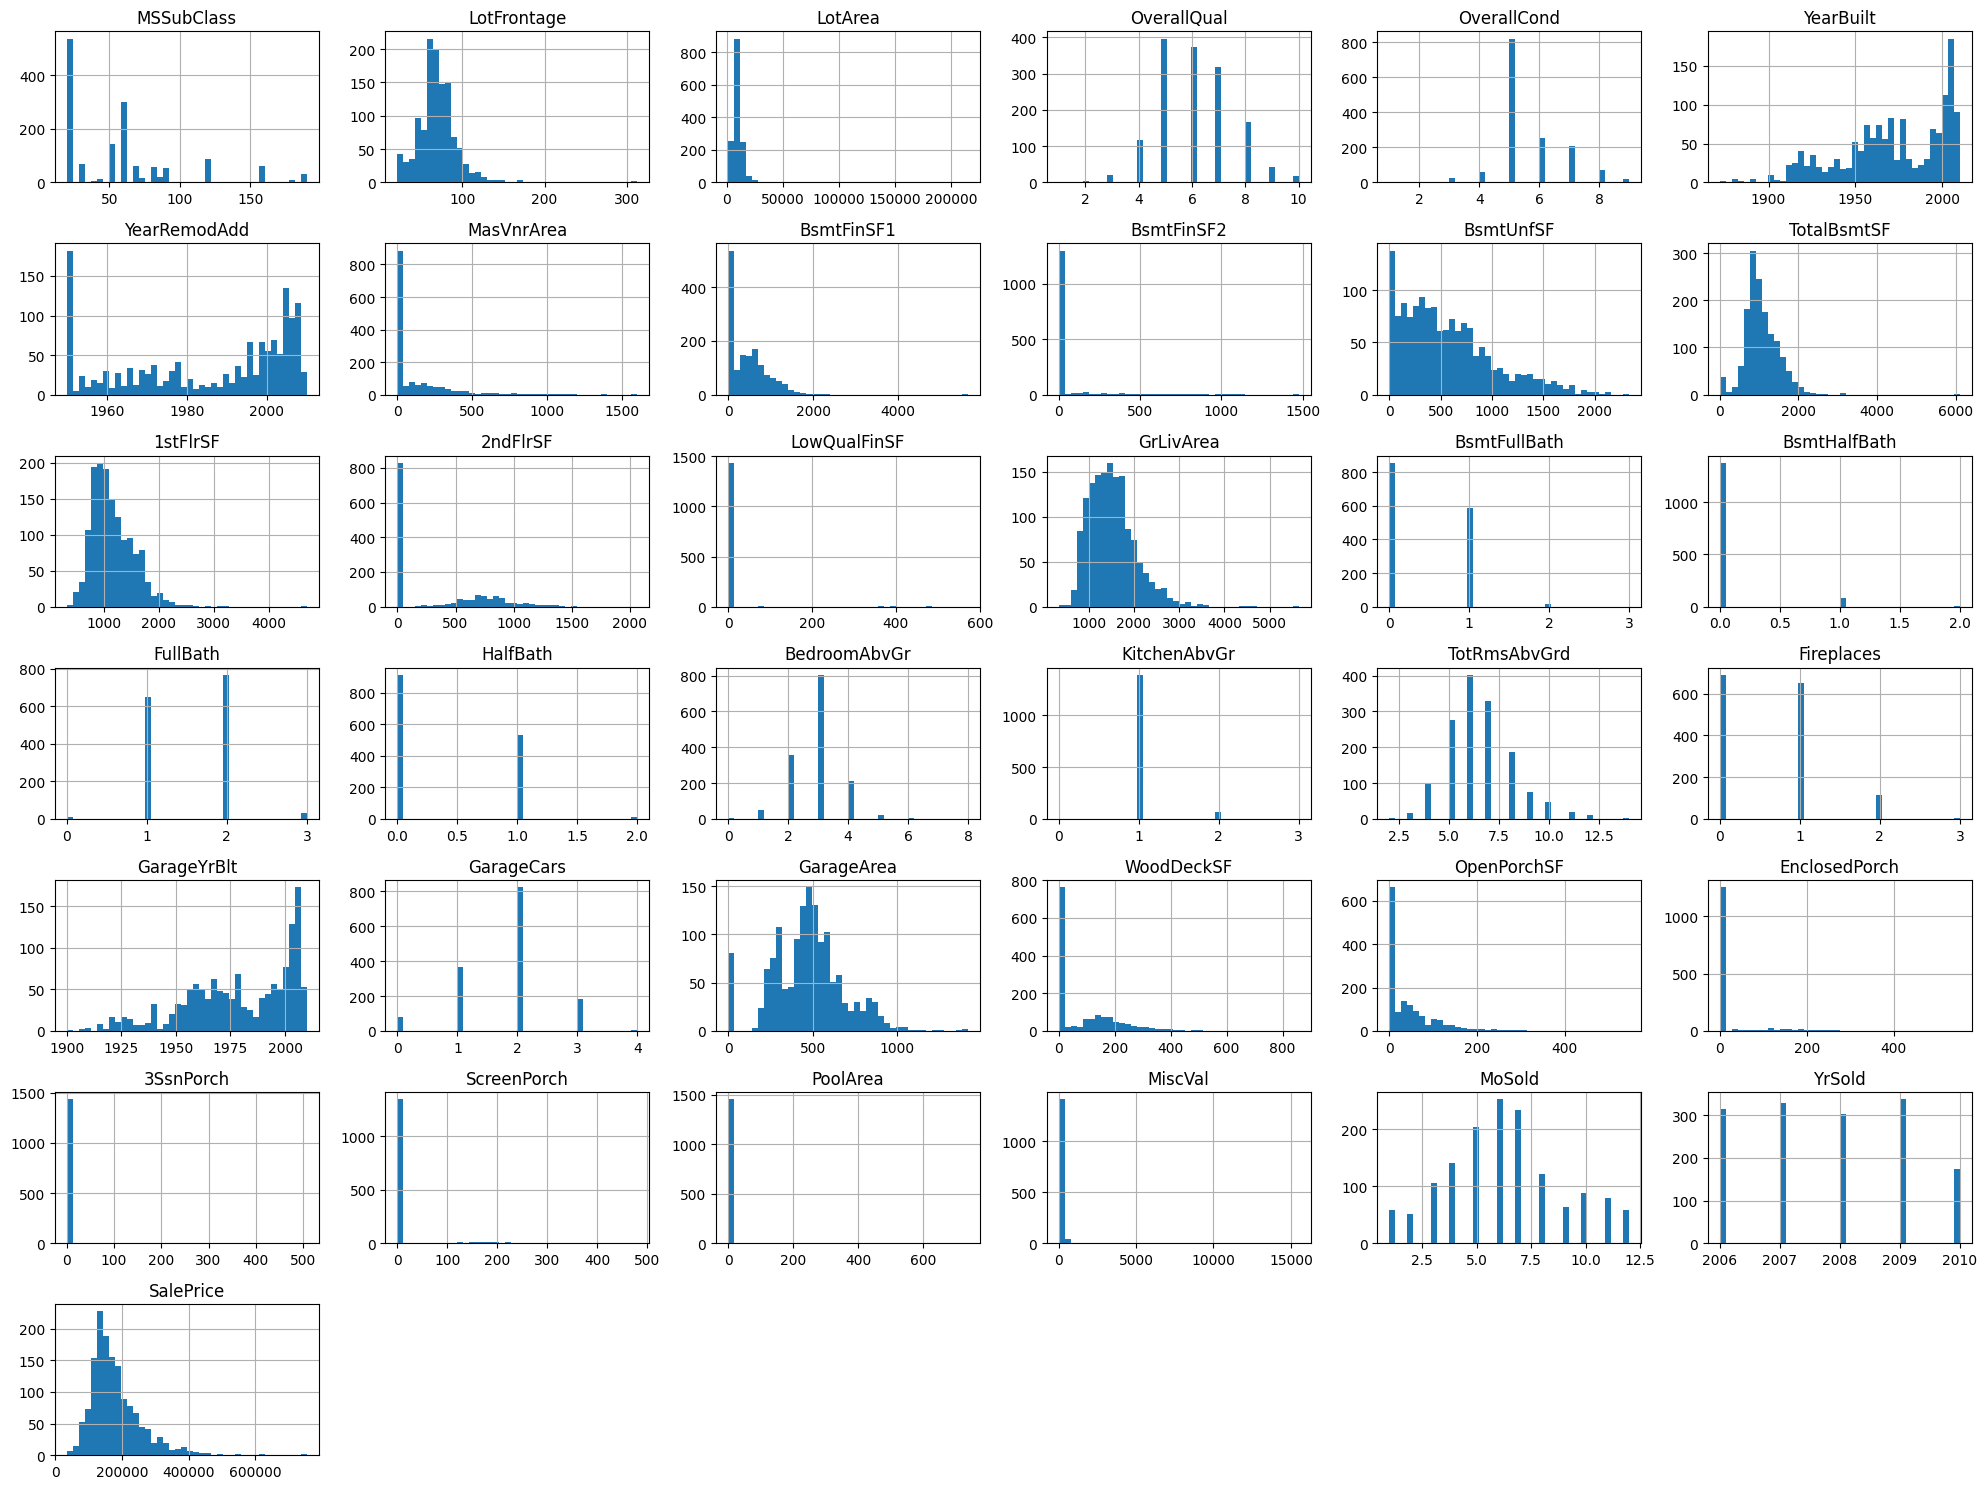

In [10]:
eda_data.hist(bins=40, figsize=(20, 15))
plt.tight_layout()
plt.show()

## 3. Define cleaning and ordinal mappings

In [11]:
none_cols = [
    'PoolQC', 'MiscFeature', 'Alley', 'Fence', 'FireplaceQu',
    'GarageType', 'GarageFinish', 'GarageQual', 'GarageCond',
    'BsmtQual', 'BsmtCond', 'BsmtExposure', 'BsmtFinType1',
    'BsmtFinType2', 'MasVnrType'
]
zero_cols = ['GarageYrBlt', 'MasVnrArea']

qual_map = {'Ex': 5, 'Gd': 4, 'TA': 3, 'Fa': 2, 'Po': 1, 'None': 0}
bsmt_exposure_map = {'Gd': 4, 'Av': 3, 'Mn': 2, 'No': 1, 'None': 0}
bsmt_fin_map = {'GLQ': 6, 'ALQ': 5, 'BLQ': 4, 'Rec': 3, 'LwQ': 2, 'Unf': 1, 'None': 0}
garage_finish_map = {'Fin': 3, 'RFn': 2, 'Unf': 1, 'None': 0}
paved_drive_map = {'Y': 2, 'P': 1, 'N': 0}
functional_map = {'Typ': 7, 'Min1': 6, 'Min2': 5, 'Mod': 4, 'Maj1': 3, 'Maj2': 2, 'Sev': 1, 'Sal': 0}
fence_map = {'GdPrv': 4, 'MnPrv': 3, 'GdWo': 2, 'MnWw': 1, 'None': 0}
utilities_map = {'AllPub': 3, 'NoSewr': 2, 'NoSeWa': 1, 'ELO': 0}

ordinal_features = [
    'OverallQual',
    'OverallCond',
    'ExterQual',
    'ExterCond',
    'BsmtQual',
    'BsmtCond',
    'HeatingQC',
    'KitchenQual',
    'FireplaceQu',
    'GarageQual',
    'GarageCond',
    'BsmtExposure',
    'BsmtFinType1',
    'BsmtFinType2',
    'GarageFinish',
    'PavedDrive',
    'Functional',
    'Fence',
    'Utilities',
    'GarageYrBlt',
    'YearBuilt',
    'YearRemodAdd',
    'YrSold',
    'MoSold',
    'MSSubClass'
]

ordinal_mappings = {
    **{col: qual_map for col in [
        'ExterQual', 'ExterCond', 'BsmtQual', 'BsmtCond', 'HeatingQC',
        'KitchenQual', 'FireplaceQu', 'GarageQual', 'GarageCond', 'PoolQC'
    ]},
    'BsmtExposure': bsmt_exposure_map,
    'BsmtFinType1': bsmt_fin_map,
    'BsmtFinType2': bsmt_fin_map,
    'GarageFinish': garage_finish_map,
    'PavedDrive': paved_drive_map,
    'Functional': functional_map,
    'Fence': fence_map,
    'Utilities': utilities_map,
}

## 4. Custom transformers

In [12]:
class HousePriceCleaner(BaseEstimator, TransformerMixin):
    def __init__(self, none_cols, zero_cols, ordinal_mappings):
        self.none_cols = none_cols
        self.zero_cols = zero_cols
        self.ordinal_mappings = ordinal_mappings

    def fit(self, X, y=None):
        X = X.copy()
        self.functional_mode_ = X['Functional'].mode().iloc[0]
        self.neighborhood_medians_ = X.groupby('Neighborhood')['LotFrontage'].median()
        self.global_median_ = X['LotFrontage'].median()
        self.electrical_mode_ = X['Electrical'].mode().iloc[0]
        return self

    def transform(self, X):
        X = X.copy()
        for col in self.none_cols:
            if col in X:
                X[col] = X[col].fillna('None')

        X['HasGarage'] = (X['GarageType'] != 'None').astype(int)

        for col in self.zero_cols:
            if col in X:
                X[col] = X[col].fillna(0)

        neighborhood_medians = X['Neighborhood'].map(self.neighborhood_medians_)
        X['LotFrontage'] = X['LotFrontage'].fillna(neighborhood_medians)
        X['LotFrontage'] = X['LotFrontage'].fillna(self.global_median_)
        X['Electrical'] = X['Electrical'].fillna(self.electrical_mode_)

        for col in ['MSSubClass', 'MoSold']:
            X[col] = X[col].astype(str)

        X['Functional'] = X['Functional'].fillna(self.functional_mode_)

        for col, mapping in self.ordinal_mappings.items():
            if col not in X:
                continue
            encoded = X[col].map(mapping)
            if encoded.isna().any():
                unknown = X.loc[encoded.isna(), col].unique()
                raise ValueError(f'Unknown categories in {col}: {unknown}')
            X[col] = encoded
        return X


class HousePriceFeatureEngineer(BaseEstimator, TransformerMixin):
    ALL_FEATURES = [
        'TotalSF', 'TotalPorchSF', 'TotalOutdoorSF',
        'TotalBathrooms', 'TotalFullBath', 'TotalHalfBath',
        'HouseAge', 'RemodAge', 'GarageAge', 'YearsSinceRemod',
        'OverallScore', 'ExteriorScore', 'GarageScore',
        'BasementScore', 'TotalQuality',
        'GarageAreaPerCar', 'HasGarage',
        'TotalBsmtFinishedSF', 'BsmtFinishedRatio',
        'BsmtUnfinishedRatio', 'HasBasement',
        'LotUtilization', 'LotFrontageRatio',
        'RoomsPerBedroom', 'AreaPerRoom', 'AreaPerBedroom',
        'HasPool', 'HasFireplace', 'Has2ndFloor',
        'HasWoodDeck', 'HasMasonryVeneer', 'HasCentralAir'
    ]

    def __init__(self, features=None):
        self.features = features

    def fit(self, X, y=None):
        return self

    def transform(self, X):
        X = X.copy()

        selected = (
            self.ALL_FEATURES
            if self.features is None
            else list(self.features)
        )

        # Validate feature names before transformation
        unknown = set(selected) - set(self.ALL_FEATURES)

        if unknown:
            raise ValueError(
                f'Unknown features: {sorted(unknown)}'
            )

        def safe_divide(numerator, denominator):
            return np.divide(
                numerator,
                denominator,
                out=np.zeros(len(X), dtype=float),
                where=(
                    np.asarray(denominator) != 0
                )
            )

        # Area
        if 'TotalSF' in selected:
            X['TotalSF'] = (
                X['TotalBsmtSF'] +
                X['1stFlrSF'] +
                X['2ndFlrSF']
            )

        if 'TotalPorchSF' in selected:
            X['TotalPorchSF'] = (
                X['OpenPorchSF'] +
                X['EnclosedPorch'] +
                X['3SsnPorch'] +
                X['ScreenPorch']
            )

        if 'TotalOutdoorSF' in selected:
            X['TotalOutdoorSF'] = (
                X['WoodDeckSF'] +
                X['OpenPorchSF'] +
                X['EnclosedPorch'] +
                X['3SsnPorch'] +
                X['ScreenPorch']
            )

        # Bathrooms
        if 'TotalBathrooms' in selected:
            X['TotalBathrooms'] = (
                X['FullBath'] +
                0.5 * X['HalfBath'] +
                X['BsmtFullBath'] +
                0.5 * X['BsmtHalfBath']
            )

        if 'TotalFullBath' in selected:
            X['TotalFullBath'] = (
                X['FullBath'] + X['BsmtFullBath']
            )

        if 'TotalHalfBath' in selected:
            X['TotalHalfBath'] = (
                X['HalfBath'] + X['BsmtHalfBath']
            )

        # Age
        if 'HouseAge' in selected:
            X['HouseAge'] = X['YrSold'] - X['YearBuilt']

        if 'RemodAge' in selected:
            X['RemodAge'] = X['YrSold'] - X['YearRemodAdd']

        if 'GarageAge' in selected:
            X['GarageAge'] = np.where(
                (X['HasGarage'] == 1) & (X['GarageYrBlt'] > 0),
                X['YrSold'] - X['GarageYrBlt'],
                0
            )

        if 'YearsSinceRemod' in selected:
            X['YearsSinceRemod'] = (
                X['YearRemodAdd'] - X['YearBuilt']
            )

        # Quality
        if 'OverallScore' in selected:
            X['OverallScore'] = (
                X['OverallQual'] * X['OverallCond']
            )

        if 'ExteriorScore' in selected:
            X['ExteriorScore'] = (
                X['ExterQual'] * X['ExterCond']
            )

        if 'GarageScore' in selected:
            X['GarageScore'] = (
                X['GarageQual'] * X['GarageCond']
            )

        if 'BasementScore' in selected:
            X['BasementScore'] = (
                X['BsmtQual'] * X['BsmtCond']
            )

        if 'TotalQuality' in selected:
            X['TotalQuality'] = (
                X['OverallQual'] +
                X['ExterQual'] +
                X['KitchenQual']
            )

        # Garage
        if 'GarageAreaPerCar' in selected:
            X['GarageAreaPerCar'] = safe_divide(
                X['GarageArea'], X['GarageCars']
            )


        if 'HasGarage' in selected:
            X['HasGarage'] = (
                X['GarageType'] != 'None'
            ).astype(int)

        # Basement
        if 'TotalBsmtFinishedSF' in selected:
            X['TotalBsmtFinishedSF'] = (
                X['BsmtFinSF1'] + X['BsmtFinSF2']
            )

        if 'BsmtFinishedRatio' in selected:
            X['BsmtFinishedRatio'] = safe_divide(
                X['BsmtFinSF1'] + X['BsmtFinSF2'],
                X['TotalBsmtSF']
            )

        if 'BsmtUnfinishedRatio' in selected:
            X['BsmtUnfinishedRatio'] = safe_divide(
                X['BsmtUnfSF'], X['TotalBsmtSF']
            )

        if 'HasBasement' in selected:
            X['HasBasement'] = (
                X['TotalBsmtSF'] > 0
            ).astype(int)

        # Lot
        if 'LotUtilization' in selected:
            X['LotUtilization'] = safe_divide(
                X['GrLivArea'], X['LotArea']
            )

        if 'LotFrontageRatio' in selected:
            X['LotFrontageRatio'] = safe_divide(
                X['LotFrontage'], X['LotArea']
            )

        # Rooms
        if 'RoomsPerBedroom' in selected:
            X['RoomsPerBedroom'] = safe_divide(
                X['TotRmsAbvGrd'], X['BedroomAbvGr']
            )

        if 'AreaPerRoom' in selected:
            X['AreaPerRoom'] = safe_divide(
                X['GrLivArea'], X['TotRmsAbvGrd']
            )

        if 'AreaPerBedroom' in selected:
            X['AreaPerBedroom'] = safe_divide(
                X['GrLivArea'], X['BedroomAbvGr']
            )

        # Binary
        binary_features = {
            'HasPool': X['PoolArea'] > 0,
            'HasFireplace': X['Fireplaces'] > 0,
            'Has2ndFloor': X['2ndFlrSF'] > 0,
            'HasWoodDeck': X['WoodDeckSF'] > 0,
            'HasMasonryVeneer': X['MasVnrArea'] > 0,
            'HasCentralAir': X['CentralAir'] == 'Y'
        }

        for feature, condition in binary_features.items():
            if feature in selected:
                X[feature] = condition.astype(int)

        return X


class HousePriceSkewnessTransformer(BaseEstimator, TransformerMixin):
    def __init__(self, skew_threshold=1.0, exclude=None):
        self.skew_threshold = skew_threshold
        self.exclude = exclude

    def fit(self, X, y=None):
        numeric_cols = X.select_dtypes(include=np.number).columns
        excluded = [] if self.exclude is None else list(self.exclude)

        self.log_features_ = []

        for col in numeric_cols:
            if (
                col in excluded
                or X[col].nunique(dropna=True) < 20
                or X[col].min(skipna=True) < 0
            ):
                continue

            if X[col].skew() > self.skew_threshold:
                self.log_features_.append(col)

        return self

    def transform(self, X):
        X = X.copy()

        for col in self.log_features_:
            # Guard against negative values appearing in later data.
            if (X[col] < 0).any():
                raise ValueError(
                    f'{col} contains negative values; log1p is not valid.'
                )

            X[col] = np.log1p(X[col])

        return X


## 5 & 6. Build preprocessing and reusable model evaluation

In [13]:
cv_strategy = KFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)


# Safe inverse transformation
def inverse_log_target(y):
    return np.maximum(np.expm1(y), 0)


def evaluate_model(
    model, X, y, cv=None,
    polynomial=True, degree=2, scaler=True,
    feature_engineering=False, engineered_features=None,
    skew_threshold=1.0, verbose=True,
    return_pipeline=False, n_jobs=1
):

    """Evaluate a regressor using cross-validation and RMSLE."""

    # 1. Numeric preprocessing
    numeric_steps = []

    if polynomial:
        numeric_steps.append((
            'polynomial',
            PolynomialFeatures(
                degree=degree,
                include_bias=False
            )
        ))

    if scaler:
        numeric_steps.append((
            'scaler',
            StandardScaler()
        ))

    numeric_pipeline = (
        Pipeline(numeric_steps)
        if numeric_steps
        else 'passthrough'
    )

    # 2. Column preprocessing
    custom_preprocessor = ColumnTransformer(
        transformers=[
            (
                'num',
                numeric_pipeline,
                make_column_selector(dtype_include=np.number)
            ),
            (
                'cat',
                OneHotEncoder(
                    handle_unknown='ignore',
                    sparse_output=False
                ),
                make_column_selector(
                    dtype_include=['object', 'category', 'string']
                )
            ),
        ],
        remainder='drop',
        verbose_feature_names_out=True,
    )

    # 3. Build preprocessing pipeline
    prep_steps = [
        (
            'cleaner',
            HousePriceCleaner(
                none_cols,
                zero_cols,
                ordinal_mappings
            )
        )
    ]

    use_feature_engineering = (
        feature_engineering or engineered_features is not None
    )

    if use_feature_engineering:
        prep_steps.append((
            'feature_engineering',
            HousePriceFeatureEngineer(
                features=engineered_features
            )
        ))

    prep_steps.extend([
        (
            'skewness',
            HousePriceSkewnessTransformer(
                skew_threshold=skew_threshold,
                exclude=ordinal_features
            )
        ),
        (
            'preprocessor',
            custom_preprocessor
        ),
    ])

    preprocessing = Pipeline(prep_steps)

    # 4. Complete model pipeline
    model_pipeline = Pipeline([
        ('preprocessing', preprocessing),
        ('model', model),
    ])

    final_model = TransformedTargetRegressor(
        regressor=model_pipeline,
        func=np.log1p,
        inverse_func=inverse_log_target,
    )

    if return_pipeline:
        return final_model

    # 5. Cross-validation
    if cv is None:
        cv = cv_strategy

    scores = -cross_val_score(
        final_model,
        X,
        y,
        cv=cv,
        scoring='neg_root_mean_squared_log_error',
        n_jobs=n_jobs,
    )

    # 6. Results
    if verbose:
        print('RMSLE scores:', scores)
        print(f'Mean RMSLE: {scores.mean():.6f}')
        print(f'Std RMSLE:  {scores.std():.6f}')

    return scores


## 7. Prepare features and target

In [14]:
X = data.drop(columns=['SalePrice', 'Id'])
y = data['SalePrice']

## 8. Evaluate models

In [15]:

def rmsle_scorer(estimator, X, y_true):
    y_pred_log = estimator.regressor_.predict(X)
    y_true_log = np.log1p(y_true)
    y_pred_log = np.maximum(y_pred_log, 0)

    return -np.sqrt(
        mean_squared_error(y_true_log, y_pred_log)
    )

def tune_model(
    model, param_grid, X, y,
    search_type='grid', cv=None, scoring=rmsle_scorer,
    n_iter=50, n_jobs=-1, verbose=1,
    random_state=42, return_train_score=True
):
    """Tune a model using GridSearchCV or RandomizedSearchCV."""

    if cv is None:
        cv = cv_strategy

    search_type = search_type.lower()

    if search_type == 'grid':
        search = GridSearchCV(
            estimator=model,
            param_grid=param_grid,
            cv=cv,
            scoring=scoring,
            n_jobs=n_jobs,
            verbose=verbose,
            return_train_score=return_train_score,
        )

    elif search_type == 'random':
        search = RandomizedSearchCV(
            estimator=model,
            param_distributions=param_grid,
            n_iter=n_iter,
            cv=cv,
            scoring=scoring,
            n_jobs=n_jobs,
            verbose=verbose,
            random_state=random_state,
            return_train_score=return_train_score,
        )

    else:
        raise ValueError(
            "search_type must be 'grid' or 'random'."
        )

    search.fit(X, y)

    print("Best parameters:")
    print(search.best_params_)

    print(f"\nBest CV RMSLE: {-search.best_score_:.6f}")

    return search.best_estimator_, search


### Linear Regression

In [16]:
linear_scores = evaluate_model(
    LinearRegression(), X, y,
    polynomial=False, scaler=True,
    feature_engineering=False, engineered_features=None,
    skew_threshold=1.0, verbose=True,
    return_pipeline=False, n_jobs=1)

RMSLE scores: [0.12316334 0.12698712 0.21182627 0.14100208 0.10995383]
Mean RMSLE: 0.142587
Std RMSLE:  0.036006


### SGD

In [17]:
sgd = SGDRegressor(
    max_iter=20000,
    tol=1e-5,
    random_state=42,
    early_stopping=False
)

sgd_pipeline = evaluate_model(
    model=sgd,
    X=X,
    y=y,
    polynomial=False,
    scaler=True,
    feature_engineering=False,
    skew_threshold=1.0,
    return_pipeline=True
)

param_grid = [
    {
        'regressor__model__penalty': ['l1', 'l2'],
        'regressor__model__alpha': [0.0001, 0.001, 0.01, 0.1],
        'regressor__model__learning_rate': ['optimal'],
        'regressor__model__average': [True, False]
    },
    {
        'regressor__model__penalty': ['l1', 'l2'],
        'regressor__model__alpha': [0.0001, 0.001, 0.01, 0.1],
        'regressor__model__learning_rate': ['adaptive'],
        'regressor__model__eta0': [0.00001, 0.0001, 0.001],
        'regressor__model__average': [True, False]
    }
]

best_sgd_model, sgd_grid_search = tune_model(
    model=sgd_pipeline, param_grid=param_grid, X=X, y=y
)

Fitting 5 folds for each of 64 candidates, totalling 320 fits
Best parameters:
{'regressor__model__alpha': 0.1, 'regressor__model__average': False, 'regressor__model__eta0': 0.001, 'regressor__model__learning_rate': 'adaptive', 'regressor__model__penalty': 'l2'}

Best CV RMSLE: 0.150981


### Ridge

In [18]:
# polinomial = False

# 1. Define Ridge model
ridge = Ridge()

# 2. Build the complete pipeline
ridge_pipeline = evaluate_model(
    model=ridge,
    X=X,
    y=y,
    polynomial=False,
    scaler=True,
    feature_engineering=False,
    skew_threshold=1.0,
    return_pipeline=True
)

# 3. Define hyperparameter grid
param_grid = {
    'regressor__model__alpha': [
        0.001, 0.01, 0.1, 1, 10, 100, 1000
    ],
    'regressor__model__solver': [
        'auto', 'svd', 'cholesky', 'lsqr'
    ],
    'regressor__model__fit_intercept': [
        True, False
    ]
}

# 4. Perform Grid Search
best_ridge_model, ridge_grid_search = tune_model(
    model=ridge_pipeline,
    param_grid=param_grid,
    X=X,
    y=y
)

Fitting 5 folds for each of 56 candidates, totalling 280 fits
Best parameters:
{'regressor__model__alpha': 10, 'regressor__model__fit_intercept': True, 'regressor__model__solver': 'lsqr'}

Best CV RMSLE: 0.136798


In [19]:
# polinomial = True

# 1. Define Ridge model
ridge = Ridge()

# 2. Build the complete pipeline
ridge_pipeline = evaluate_model(
    model=ridge,
    X=X,
    y=y,
    polynomial=True,
    scaler=True,
    feature_engineering=False,
    skew_threshold=1.0,
    return_pipeline=True
)

# 3. Define hyperparameter grid
param_grid = {
    'regressor__model__alpha': [
        0.001, 0.01, 0.1, 1, 10, 100, 1000
    ],
    'regressor__model__solver': [
        'auto', 'svd', 'cholesky', 'lsqr'
    ],
    'regressor__model__fit_intercept': [
        True, False
    ]
}

# 4. Perform Grid Search
best_ridge_model, ridge_grid_search = tune_model(
    model=ridge_pipeline,
    param_grid=param_grid,
    X=X,
    y=y
)

Fitting 5 folds for each of 56 candidates, totalling 280 fits
Best parameters:
{'regressor__model__alpha': 1000, 'regressor__model__fit_intercept': True, 'regressor__model__solver': 'auto'}

Best CV RMSLE: 0.155764


### lasso

In [20]:
# polynomial = False

# 1. Define Lasso model
lasso = Lasso(max_iter=50000)

# 2. Build the complete pipeline
lasso_pipeline = evaluate_model(
    model=lasso,
    X=X,
    y=y,
    polynomial=False,
    scaler=True,
    feature_engineering=False,
    skew_threshold=1.0,
    return_pipeline=True
)

# 3. Define hyperparameter grid
param_grid = {
    'regressor__model__alpha': [
        0.0001, 0.001, 0.01, 0.1, 1, 10, 100
    ],
    'regressor__model__fit_intercept': [
        True, False
    ]
}

# 4. Perform Grid Search
best_lasso_model, lasso_grid_search = tune_model(
    model=lasso_pipeline,
    param_grid=param_grid,
    X=X,
    y=y
)

Fitting 5 folds for each of 14 candidates, totalling 70 fits
Best parameters:
{'regressor__model__alpha': 0.0001, 'regressor__model__fit_intercept': True}

Best CV RMSLE: 0.136391


In [21]:
# polynomial = True

# 1. Define Lasso model
lasso = Lasso(max_iter=50000)

# 2. Build the complete pipeline
lasso_pipeline = evaluate_model(
    model=lasso,
    X=X,
    y=y,
    polynomial=True,
    scaler=True,
    feature_engineering=False,
    skew_threshold=1.0,
    return_pipeline=True
)

# 3. Define hyperparameter grid
param_grid = {
    'regressor__model__alpha': [
        0.0001, 0.001, 0.01, 0.1, 1, 10, 100
    ],
    'regressor__model__fit_intercept': [
        True, False
    ]
}

# 4. Perform Grid Search
best_lasso_model, lasso_grid_search = tune_model(
    model=lasso_pipeline,
    param_grid=param_grid,
    X=X,
    y=y
)

Fitting 5 folds for each of 14 candidates, totalling 70 fits
Best parameters:
{'regressor__model__alpha': 0.01, 'regressor__model__fit_intercept': True}

Best CV RMSLE: 0.144044


### Elastic Net Regression

In [22]:
# polinomial = False

# 1. Define ElasticNet model
elasticnet = ElasticNet(max_iter=50000)

# 2. Build the complete pipeline
elasticnet_pipeline = evaluate_model(
    model=elasticnet,
    X=X,
    y=y,
    polynomial=False,
    scaler=True,
    feature_engineering=False,
    skew_threshold=1.0,
    return_pipeline=True
)

# 3. Define hyperparameter grid
param_grid = {
    'regressor__model__alpha': [
        0.0001, 0.001, 0.01, 0.1, 1, 10, 100
    ],
    'regressor__model__l1_ratio': [
        0.1, 0.3, 0.5, 0.7, 0.9
    ],
    'regressor__model__fit_intercept': [
        True, False
    ]
}

# 4. Perform Grid Search
best_elasticnet_model, elasticnet_grid_search = tune_model(
    model=elasticnet_pipeline,
    param_grid=param_grid,
    X=X,
    y=y
)

Fitting 5 folds for each of 70 candidates, totalling 350 fits
Best parameters:
{'regressor__model__alpha': 0.001, 'regressor__model__fit_intercept': True, 'regressor__model__l1_ratio': 0.3}

Best CV RMSLE: 0.135108


In [23]:
# polinomial = True

# 1. Define ElasticNet model
elasticnet = ElasticNet(max_iter=50000)

# 2. Build the complete pipeline
elasticnet_pipeline = evaluate_model(
    model=elasticnet,
    X=X,
    y=y,
    polynomial=True,
    scaler=True,
    feature_engineering=False,
    skew_threshold=1.0,
    return_pipeline=True
)

# 3. Define hyperparameter grid
param_grid = {
    'regressor__model__alpha': [
        0.0001, 0.001, 0.01, 0.1, 1, 10, 100
    ],
    'regressor__model__l1_ratio': [
        0.1, 0.3, 0.5, 0.7, 0.9
    ],
    'regressor__model__fit_intercept': [
        True, False
    ]
}

# 4. Perform Grid Search
best_elasticnet_model, elasticnet_grid_search = tune_model(
    model=elasticnet_pipeline,
    param_grid=param_grid,
    X=X,
    y=y
)

Fitting 5 folds for each of 70 candidates, totalling 350 fits
Best parameters:
{'regressor__model__alpha': 0.1, 'regressor__model__fit_intercept': True, 'regressor__model__l1_ratio': 0.1}

Best CV RMSLE: 0.145175


In [24]:
!pwd


/content


In [27]:
!git status --short
!ls Notebooks/

house_prices.ipynb
